# Food delivery in Hanoi and Ho Chi Minh City: orders, weather and air quality

Three live sources flow through Kafka into Cassandra:

| Source | Table | What it holds |
| --- | --- | --- |
| OpenWeatherMap (Task 1) | `weatherreport` | Weather for Hanoi and Ho Chi Minh City |
| Faker (Task 2) | `fakerdata` | Synthetic delivery orders, 10 fields |
| Open-Meteo (Task 3) | `airquality` | PM2.5, PM10 and air quality indexes |

Faker orders are synthetic, so differences between cities in plots B and C are random. Plot A uses real data.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from cassandrautils import getWeatherDF, getFakerDF, getAirQualityDF

sns.set_theme(style="whitegrid", font_scale=1.2)

## 1. Load the three tables from Cassandra

In [2]:
weather = getWeatherDF()
faker = getFakerDF()
air = getAirQualityDF()

# Real datetime columns, and Kelvin converted to degrees Celsius
weather["time"] = pd.to_datetime(weather["forecastdate"])
weather["temp_c"] = weather["temp"] - 273.15
air["time"] = pd.to_datetime(air["report_time"])
faker["time"] = pd.to_datetime(faker["ordered_at"])

print("weather:", weather.shape, " faker:", faker.shape, " air quality:", air.shape)

weather: (18, 14)  faker: (91, 11)  air quality: (13, 7)


### Weather (Task 1)

In [3]:
print(weather["location"].value_counts())
weather.head()

location
Ho Chi Minh City    9
Hanoi               9
Name: count, dtype: int64


,location,forecastdate,description,feels_like,humidity,pressure,sunrise,sunset,temp,temp_max,temp_min,wind,time,temp_c
0,Ho Chi Minh City,2026-11-26 05:19:17,scattered clouds,313.519989,64.0,1010.0,1795647219,1795688862,306.519989,307.160004,306.519989,2.57,2026-11-26 05:19:17,33.369989
1,Ho Chi Minh City,2026-11-26 05:20:17,scattered clouds,313.519989,64.0,1010.0,1795647219,1795688862,306.519989,307.160004,306.519989,2.57,2026-11-26 05:20:17,33.369989
2,Ho Chi Minh City,2026-11-26 05:21:18,scattered clouds,313.519989,64.0,1010.0,1795647219,1795688862,306.519989,307.160004,306.519989,2.57,2026-11-26 05:21:18,33.369989
3,Ho Chi Minh City,2026-11-26 05:22:18,scattered clouds,313.519989,64.0,1010.0,1795647219,1795688862,306.519989,307.160004,306.519989,2.57,2026-11-26 05:22:18,33.369989
4,Ho Chi Minh City,2026-11-26 05:23:19,scattered clouds,313.519989,64.0,1010.0,1795647219,1795688862,306.519989,307.160004,306.519989,2.57,2026-11-26 05:23:19,33.369989


### Faker orders (Task 2)

In [4]:
print(faker["city"].value_counts())
faker.head()

city
Hanoi               49
Ho Chi Minh City    42
Name: count, dtype: int64


,city,ordered_at,order_id,address,customer_name,customer_rating,delivery_minutes,item_category,order_amount_vnd,payment_method,time
0,Ho Chi Minh City,2026-11-26 05:19:33,2c2715bd-ec9d-413a-a071-ae7542374aa6,112 Dương Ngõ,Bảo Hoàng,5,57,Coffee,475000,card,2026-11-26 05:19:33
1,Ho Chi Minh City,2026-11-26 05:19:58,243d7ee6-8b25-4930-96d1-dbedd3e39971,282 Jane Tổ,Lâm Đặng,1,30,Rice,60000,card,2026-11-26 05:19:58
2,Ho Chi Minh City,2026-11-26 05:20:28,cf793063-fc3c-415e-aea1-72e0702ced85,200 Jane Ngõ,Hạnh Dương,3,60,Bubble tea,334000,card,2026-11-26 05:20:28
3,Ho Chi Minh City,2026-11-26 05:20:36,5cfe0d7b-16ed-49ec-b35c-8e432c52f027,696 Jane Dãy,Bảo Hoàng Đặng,5,24,Coffee,368000,card,2026-11-26 05:20:36
4,Ho Chi Minh City,2026-11-26 05:20:48,83a4cd97-4862-4b6b-b6df-74f554305070,98 Đặng Hẻm,Thành Vũ,1,30,Banh mi,287000,cash,2026-11-26 05:20:48


### Air quality (Task 3)

In [5]:
print(air["location"].value_counts())
air.head()

location
Hanoi               7
Ho Chi Minh City    6
Name: count, dtype: int64


,location,report_time,european_aqi,pm10,pm2_5,us_aqi,time
0,Ho Chi Minh City,2026-11-26 05:21:57,78,38.5,37.0,125,2026-11-26 05:21:57
1,Ho Chi Minh City,2026-11-26 05:22:59,78,38.5,37.0,125,2026-11-26 05:22:59
2,Ho Chi Minh City,2026-11-26 05:24:01,78,38.5,37.0,125,2026-11-26 05:24:01
3,Ho Chi Minh City,2026-11-26 05:25:03,78,38.5,37.0,125,2026-11-26 05:25:03
4,Ho Chi Minh City,2026-11-26 05:26:05,78,38.5,37.0,125,2026-11-26 05:26:05


## 2. Plot A: temperature and air quality per city

**Why it is useful:** shows which city is hotter and which has the worse air right now, and how both move over time. Riders work outside, so both numbers matter. The dashed line marks US AQI 100, the point where air becomes unhealthy for sensitive groups.

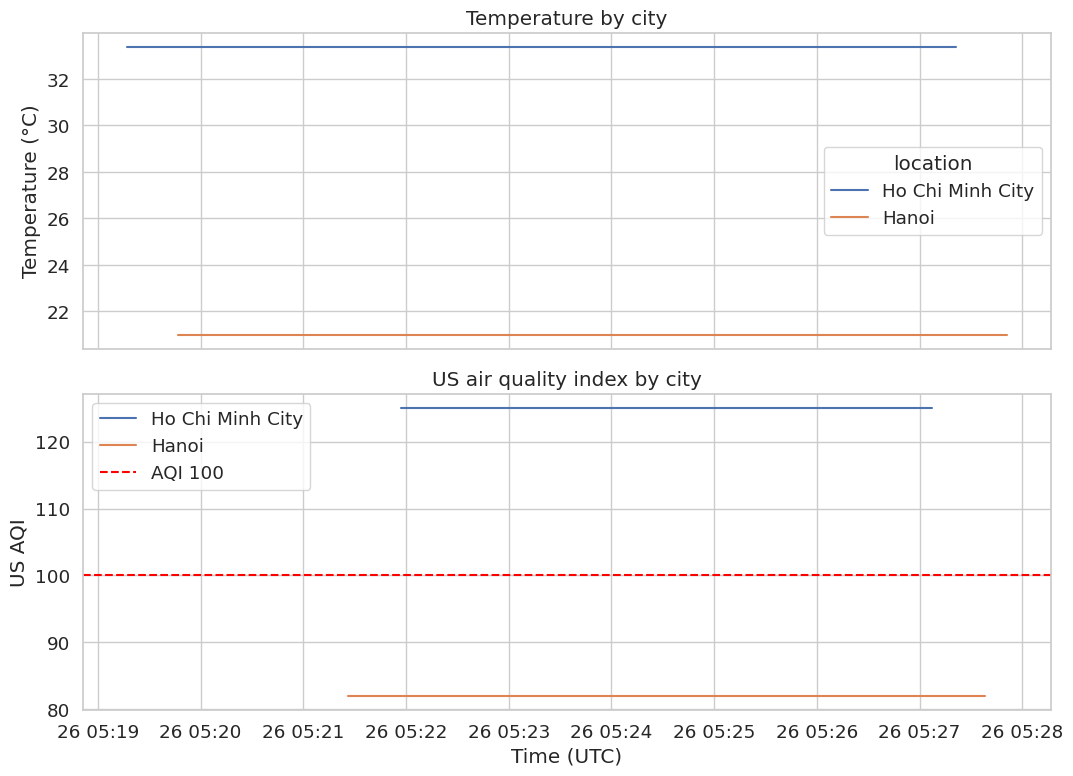

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

sns.lineplot(data=weather, x="time", y="temp_c", hue="location", ax=axes[0])
axes[0].set_title("Temperature by city")
axes[0].set_ylabel("Temperature (°C)")

sns.lineplot(data=air, x="time", y="us_aqi", hue="location", ax=axes[1])
axes[1].axhline(100, color="red", linestyle="--", label="AQI 100")
axes[1].set_title("US air quality index by city")
axes[1].set_ylabel("US AQI")
axes[1].set_xlabel("Time (UTC)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Analysis (write after the run):**
- Which city is hotter, and by how many degrees?
- Which city has the higher US AQI, and does either cross the AQI 100 line?
- What would that mean for riders (heat, masks, shift limits)?

## 3. Plot B: what sells where

**Why it is useful:** shows which food categories bring in orders and money in each city, which guides stock and promotions.

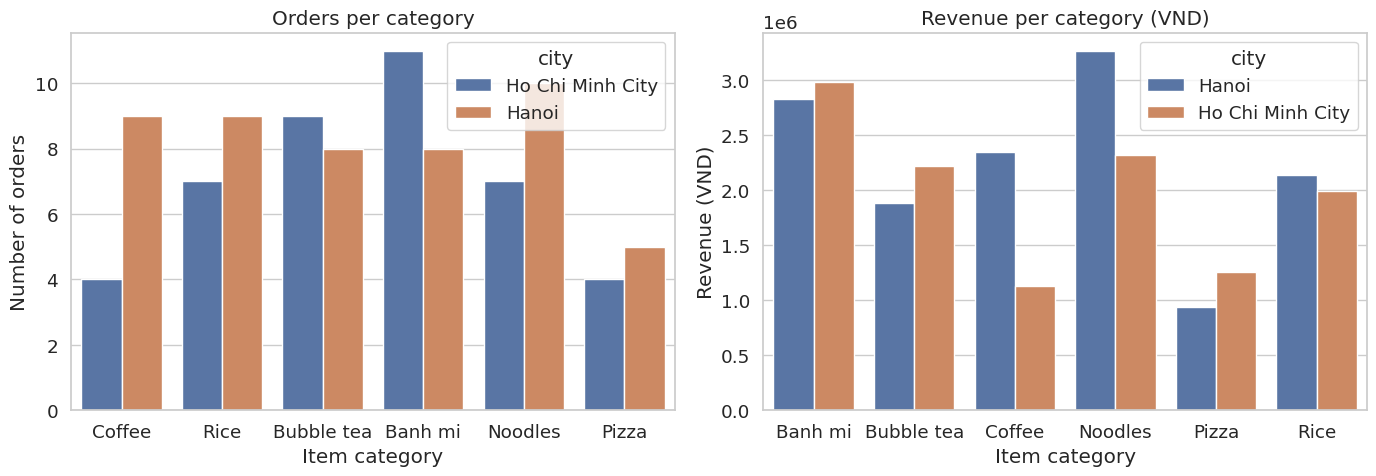

In [7]:
revenue = (faker.groupby(["item_category", "city"], as_index=False)["order_amount_vnd"].sum()
           .rename(columns={"order_amount_vnd": "revenue_vnd"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=faker, x="item_category", hue="city", ax=axes[0])
axes[0].set_title("Orders per category")
axes[0].set_xlabel("Item category")
axes[0].set_ylabel("Number of orders")

sns.barplot(data=revenue, x="item_category", y="revenue_vnd", hue="city", ax=axes[1])
axes[1].set_title("Revenue per category (VND)")
axes[1].set_xlabel("Item category")
axes[1].set_ylabel("Revenue (VND)")

plt.tight_layout()
plt.show()

**Analysis (write after the run):**
- Which category leads in orders and in revenue in each city?
- Do the two cities differ? (The orders are synthetic, so any difference is random.)

## 4. Plot C: orders by air quality when they were placed

**Why it is useful:** joins all the sources. Each order is matched to the nearest air quality reading of its own city, so we can count how many deliveries took place in good, moderate or unhealthy air. A platform could use this number for a rider safety policy.

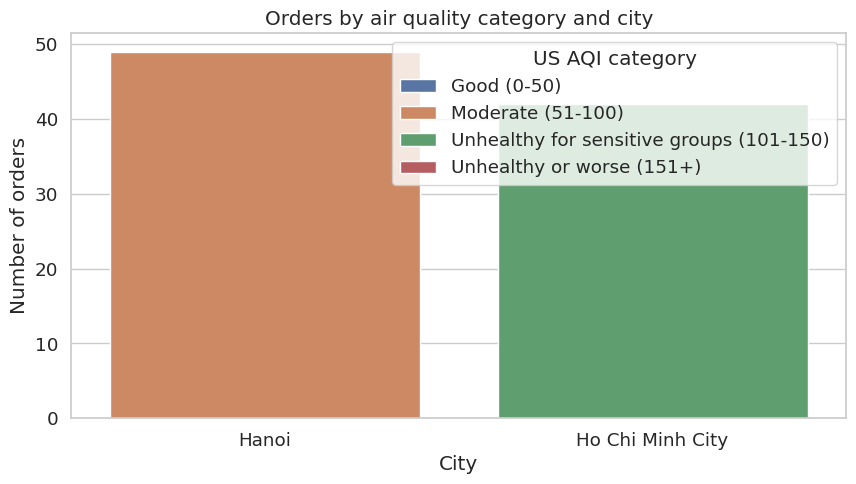

In [8]:
orders = faker.sort_values("time")
aqi = (air[["location", "time", "us_aqi"]]
       .rename(columns={"location": "city"})
       .sort_values("time"))

# Match every order to the closest air quality reading of the same city (within 2 hours)
merged = pd.merge_asof(orders, aqi, on="time", by="city",
                       direction="nearest", tolerance=pd.Timedelta("2h"))

bins = [0, 50, 100, 150, 500]
labels = ["Good (0-50)", "Moderate (51-100)",
          "Unhealthy for sensitive groups (101-150)", "Unhealthy or worse (151+)"]
merged["aqi_category"] = pd.cut(merged["us_aqi"], bins=bins, labels=labels)

counts = (merged.groupby(["city", "aqi_category"], observed=True)
          .size().reset_index(name="orders"))

plt.figure(figsize=(10, 5))
sns.barplot(data=counts, x="city", y="orders", hue="aqi_category")
plt.title("Orders by air quality category and city")
plt.xlabel("City")
plt.ylabel("Number of orders")
plt.legend(title="US AQI category")
plt.show()

**Analysis (write after the run):**
- In which air quality category did most orders fall, in each city?
- What share of orders were placed when air was unhealthy for sensitive groups or worse?
- What policy could the platform set with that number?